In [9]:
import pandas as pd
import numpy as np

# ── LOAD ─────────────────────────────────────────────────────────────────────
df = pd.read_csv("/Users/aliabonanno/public_policy_project/master_panel_monthly_fc.csv",
                 dtype={"FIPS": str})
df["FIPS"] = df["FIPS"].str.zfill(5)

print(f"Panel: {len(df):,} rows | {df['FIPS'].nunique():,} counties | "
      f"Years: {df['year'].min()}–{df['year'].max()}")

# ── VARIABLES TO SUMMARIZE ────────────────────────────────────────────────────
vars_dict = {
    # Outcomes
    "Log res. sales per customer":     "log_res_sales_per_customer",
    "Log implied price ($/MWh)":       "log_implied_price",
    # Treatment — hot bins
    "Days in 20–25°C bin":             "bin7_20to25",
    "Days in 25–30°C bin":             "bin8_25to30",
    "Days above 30°C":                 "bin9_over30",
    # Controls
    "Monthly precipitation (mm)":      "prcp_monthly_mm",
    # Moderators
    "Poverty rate (% < 150% FPL)":     "pct_below_150pct_poverty",
    "Fixed monthly charge ($/mo.)":    "fixed_charge_county",
}

# ── BUILD TABLE ───────────────────────────────────────────────────────────────
rows = []
for label, col in vars_dict.items():
    if col not in df.columns:
        print(f"WARNING: {col} not found")
        continue
    s = df[col].dropna()
    rows.append({
        "Variable":  label,
        "N":         f"{len(s):,}",
        "Mean":      f"{s.mean():.3f}",
        "SD":        f"{s.std():.3f}",
        "P10":       f"{s.quantile(0.10):.3f}",
        "P25":       f"{s.quantile(0.25):.3f}",
        "P50":       f"{s.quantile(0.50):.3f}",
        "P75":       f"{s.quantile(0.75):.3f}",
        "P90":       f"{s.quantile(0.90):.3f}",
    })

table = pd.DataFrame(rows)

# ── PRINT ─────────────────────────────────────────────────────────────────────
print("\nTable 1 — Summary Statistics (Full Panel, County-Month)\n")
print(table.to_string(index=False))

# ── SAVE ──────────────────────────────────────────────────────────────────────
table.to_csv("/Users/aliabonanno/public_policy_project/table1_full_panel.csv",
             index=False)
print("\nSaved table1_full_panel.csv")

Panel: 335,878 rows | 2,814 counties | Years: 2015–2024

Table 1 — Summary Statistics (Full Panel, County-Month)

                    Variable       N   Mean     SD    P10    P25    P50     P75     P90
 Log res. sales per customer 335,875 -0.109  0.324 -0.539 -0.333 -0.111   0.129   0.310
   Log implied price ($/MWh) 335,867  4.842  0.245  4.583  4.686  4.808   4.957   5.130
         Days in 20–25°C bin 333,466  5.738  7.292  0.000  0.000  2.000  11.000  18.000
         Days in 25–30°C bin 333,466  3.720  7.522  0.000  0.000  0.000   3.000  16.000
             Days above 30°C 333,466  0.206  1.530  0.000  0.000  0.000   0.000   0.000
  Monthly precipitation (mm) 333,466 87.130 63.206 15.970 40.030 76.640 121.150 168.615
 Poverty rate (% < 150% FPL) 335,578  0.251  0.086  0.149  0.188  0.243   0.303   0.363
Fixed monthly charge ($/mo.) 335,878 11.864  4.487  7.488  9.298 11.093  13.981  16.904

Saved table1_full_panel.csv


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("/Users/aliabonanno/public_policy_project/master_panel_monthly_fc.csv",
                 dtype={"FIPS": str})

median_pov = df["pct_below_150pct_poverty"].median()
df["poverty_group"] = np.where(df["pct_below_150pct_poverty"] >= median_pov,
                                "High poverty", "Low poverty")

monthly = (df.groupby(["month", "poverty_group"])
           ["log_res_sales_per_customer"]
           .mean().reset_index())

print(monthly.pivot(index="month", columns="poverty_group",
                    values="log_res_sales_per_customer").round(3))

poverty_group  High poverty  Low poverty
month                                   
1                     0.184        0.034
2                     0.001       -0.133
3                    -0.110       -0.216
4                    -0.302       -0.400
5                    -0.213       -0.379
6                     0.018       -0.167
7                     0.216        0.038
8                     0.181       -0.004
9                    -0.025       -0.236
10                   -0.223       -0.383
11                   -0.190       -0.300
12                    0.051       -0.062


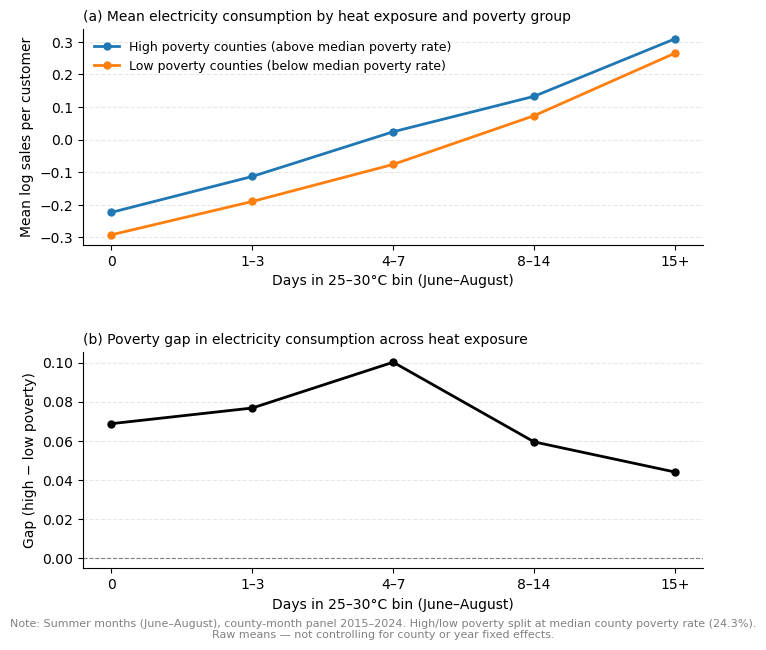

Saved fig_heat_gap.png


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── LOAD ─────────────────────────────────────────────────────────────────────
df = pd.read_csv("/Users/aliabonanno/public_policy_project/master_panel_monthly_fc.csv",
                 dtype={"FIPS": str})

# Summer months only
summer = df[df["month"].isin([6, 7, 8])].copy()

# Split at median poverty
median_pov = summer["pct_below_150pct_poverty"].median()
summer["poverty_group"] = np.where(
    summer["pct_below_150pct_poverty"] >= median_pov,
    "High poverty", "Low poverty"
)

# ── PANEL (a): MEAN LOG SALES BY BIN8 DAYS, SPLIT BY POVERTY ─────────────────
# Bin days in 25-30C into discrete buckets
bins   = [-1, 0, 3, 7, 14, 31]
labels = ["0", "1–3", "4–7", "8–14", "15+"]
summer["heat_bucket"] = pd.cut(summer["bin8_25to30"], bins=bins, labels=labels)

panel_a = (summer.groupby(["heat_bucket", "poverty_group"], observed=True)
           ["log_res_sales_per_customer"]
           .mean().reset_index())

high_a = panel_a[panel_a["poverty_group"] == "High poverty"]
low_a  = panel_a[panel_a["poverty_group"] == "Low poverty"]

# ── PANEL (b): DIFFERENCE ─────────────────────────────────────────────────────
diff = high_a["log_res_sales_per_customer"].values - low_a["log_res_sales_per_customer"].values

# ── PLOT ──────────────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7))
fig.subplots_adjust(hspace=0.5)

x = np.arange(len(labels))

# Panel (a)
ax1.plot(x, high_a["log_res_sales_per_customer"].values,
         color="#1f77b4", linewidth=2, marker="o", markersize=5,
         label="High poverty counties (above median poverty rate)")
ax1.plot(x, low_a["log_res_sales_per_customer"].values,
         color="#ff7f0e", linewidth=2, marker="o", markersize=5,
         label="Low poverty counties (below median poverty rate)")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=10)
ax1.set_xlabel("Days in 25–30°C bin (June–August)", fontsize=10)
ax1.set_ylabel("Mean log sales per customer", fontsize=10)
ax1.set_title("(a) Mean electricity consumption by heat exposure and poverty group",
              fontsize=10, loc="left")
ax1.legend(fontsize=9, frameon=False)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.grid(axis="y", alpha=0.3, linestyle="--")

# Panel (b)
ax2.plot(x, diff, color="black", linewidth=2, marker="o", markersize=5)
ax2.axhline(0, color="grey", linewidth=0.8, linestyle="--")
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=10)
ax2.set_xlabel("Days in 25–30°C bin (June–August)", fontsize=10)
ax2.set_ylabel("Gap (high − low poverty)", fontsize=10)
ax2.set_title("(b) Poverty gap in electricity consumption across heat exposure",
              fontsize=10, loc="left")
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.grid(axis="y", alpha=0.3, linestyle="--")

fig.text(0.5, 0.01,
         "Note: Summer months (June–August), county-month panel 2015–2024. "
         "High/low poverty split at median county poverty rate (24.3%).\n"
         "Raw means — not controlling for county or year fixed effects.",
         ha="center", fontsize=8, color="grey")

plt.savefig("/Users/aliabonanno/public_policy_project/figures/fig_heat_gap.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved fig_heat_gap.png")

In [4]:
import pandas as pd
import numpy as np

master = pd.read_csv("/Users/aliabonanno/public_policy_project/master_panel_monthly_fc.csv",
                     dtype={"FIPS": str})

# Correct implied price — already in $/MWh, just exponentiate
implied_price_per_mwh = np.exp(master["log_implied_price"].dropna().mean())
print(f"Mean implied price: ${implied_price_per_mwh:.2f}/MWh "
      f"({implied_price_per_mwh/10:.2f} cents/kWh)")

# Summer cooperative counties
summer_coop = master[
    (master["month"].isin([6, 7, 8])) &
    (master["dominant_ownership_type"] == "Cooperative")
].copy()

mean_b8 = summer_coop["bin8_25to30"].mean()
mean_b9 = summer_coop["bin9_over30"].mean()
mean_customers = summer_coop["res_customers_total"].mean()
mean_sales_per_customer = np.exp(master["log_res_sales_per_customer"].dropna().mean())

print(f"\nCooperative county summer stats:")
print(f"  Mean days in bin 8: {mean_b8:.2f}")
print(f"  Mean days in bin 9: {mean_b9:.2f}")
print(f"  Mean customers per county-month: {mean_customers:,.0f}")
print(f"  Mean sales per customer (MWh): {mean_sales_per_customer:.3f}")

# Poverty deviation: 75th percentile county vs mean
mean_pov = master["pct_below_150pct_poverty"].mean()
p75_pov  = master["pct_below_150pct_poverty"].quantile(0.75)
pov_dev  = p75_pov - mean_pov
print(f"\nPoverty deviation (P75 - mean): {pov_dev:.3f}")

# Spec 5 cooperative amplification coefficients
coef_b8_coop = -0.0245
coef_b9_coop = -0.0433

# Consumption shortfall per customer per summer month
# = (coef_b8 * days_b8 + coef_b9 * days_b9) * pov_deviation * mean_consumption
# This gives the log-point reduction, approximately equal to percent reduction
log_shortfall = (coef_b8_coop * mean_b8 + coef_b9_coop * mean_b9) * pov_dev
pct_shortfall = abs(log_shortfall) * 100
mwh_shortfall = abs(log_shortfall) * mean_sales_per_customer
dollar_shortfall_per_customer = mwh_shortfall * implied_price_per_mwh

print(f"\nConsumption shortfall per customer per summer month:")
print(f"  Log-point reduction: {log_shortfall:.4f}")
print(f"  Approximate % reduction: {pct_shortfall:.2f}%")
print(f"  MWh shortfall: {mwh_shortfall:.4f} MWh")
print(f"  Dollar value: ${dollar_shortfall_per_customer:.2f}/customer/month")

# Total unique cooperative county customers in one summer
# Use one year to avoid triple counting
summer_coop_2023 = master[
    (master["month"].isin([6, 7, 8])) &
    (master["dominant_ownership_type"] == "Cooperative") &
    (master["year"] == 2023)
].copy()

total_customers_annual = summer_coop_2023["res_customers_total"].sum()
total_dollar_shortfall = dollar_shortfall_per_customer * total_customers_annual * 3  # 3 summer months

print(f"\nTotal cooperative residential customers (2023): "
      f"{total_customers_annual:,}")
print(f"Total aggregate summer shortfall (2023): "
      f"${total_dollar_shortfall/1e6:.1f} million")
print(f"Per household annually: ${dollar_shortfall_per_customer * 3:.2f}")

Mean implied price: $126.76/MWh (12.68 cents/kWh)

Cooperative county summer stats:
  Mean days in bin 8: 11.91
  Mean days in bin 9: 1.05
  Mean customers per county-month: 55,518
  Mean sales per customer (MWh): 0.896

Poverty deviation (P75 - mean): 0.052

Consumption shortfall per customer per summer month:
  Log-point reduction: -0.0177
  Approximate % reduction: 1.77%
  MWh shortfall: 0.0159 MWh
  Dollar value: $2.01/customer/month

Total cooperative residential customers (2023): 29,508,342.0
Total aggregate summer shortfall (2023): $178.1 million
Per household annually: $6.04


In [2]:
import pandas as pd
import numpy as np
from scipy import stats

# States with PUC low-income discount programs (from CGEP Figure 1)
discount_states = {
    'WA', 'OR', 'CA', 'NV', 'AZ', 'UT', 'CO', 'ND', 'MN', 'IL', 
    'IN', 'MI', 'OH', 'KY', 'WV', 'VA', 'NC', 'TN', 'GA', 'ME', 
    'NH', 'NY', 'NJ', 'MA', 'CT', 'MD', 'PA'
}

# Load master panel
master = pd.read_csv("/Users/aliabonanno/public_policy_project/master_panel_monthly_fc.csv",
                     dtype={"FIPS": str})

# Extract state FIPS (first 2 digits) and map to state abbreviations
# You may already have a state variable — check first
print(master.columns.tolist())
print(master["FIPS"].head(10))

['FIPS', 'year', 'month', 'res_revenue_000_total', 'res_sales_mwh_total', 'res_customers_total', 'n_utilities', 'implied_price_per_mwh', 'res_sales_per_customer', 'log_res_sales_per_customer', 'log_implied_price', 'dominant_ownership_type', 'bin1_under_neg5', 'bin2_neg5to0', 'bin3_0to5', 'bin4_5to10', 'bin5_10to15', 'bin6_15to20', 'bin7_20to25', 'bin8_25to30', 'bin9_over30', 'prcp_monthly_mm', 'prcp_monthly_mm_sq', 'pct_below_150pct_poverty', 'total_pop', 'median_hh_income', 'pct_white', 'pct_black', 'pct_hispanic', 'pct_bachelors_plus', 'unemployment_rate', 'pct_electric_heat', 'rucc_score', 'rural', 'fixed_charge_county', 'poverty_demeaned', 'fc_demeaned', 'covid', 'bin1_under_neg5_x_pov', 'bin2_neg5to0_x_pov', 'bin3_0to5_x_pov', 'bin4_5to10_x_pov', 'bin5_10to15_x_pov', 'bin7_20to25_x_pov', 'bin8_25to30_x_pov', 'bin9_over30_x_pov', 'bin7_20to25_x_pov_x_fc', 'bin8_25to30_x_pov_x_fc', 'bin9_over30_x_pov_x_fc', 'is_coop', 'is_municipal', 'bin7_20to25_x_pov_x_coop', 'bin7_20to25_x_pov_x_

In [4]:
import pandas as pd
import numpy as np
from scipy import stats

master = pd.read_csv("/Users/aliabonanno/public_policy_project/master_panel_monthly_fc.csv",
                     dtype={"FIPS": str})

# State FIPS to abbreviation mapping
state_fips_map = {
    '01':'AL','02':'AK','04':'AZ','05':'AR','06':'CA','08':'CO','09':'CT',
    '10':'DE','11':'DC','12':'FL','13':'GA','15':'HI','16':'ID','17':'IL',
    '18':'IN','19':'IA','20':'KS','21':'KY','22':'LA','23':'ME','24':'MD',
    '25':'MA','26':'MI','27':'MN','28':'MS','29':'MO','30':'MT','31':'NE',
    '32':'NV','33':'NH','34':'NJ','35':'NM','36':'NY','37':'NC','38':'ND',
    '39':'OH','40':'OK','41':'OR','42':'PA','44':'RI','45':'SC','46':'SD',
    '47':'TN','48':'TX','49':'UT','50':'VT','51':'VA','53':'WA','54':'WV',
    '55':'WI','56':'WY'
}

# States with PUC low-income discount programs (CGEP Figure 1)
discount_states = {
    'WA','OR','CA','NV','AZ','UT','CO','ND','MN','IL','IN','MI','OH',
    'KY','WV','VA','NC','TN','GA','ME','NH','NY','NJ','MA','CT','MD','PA','DC'
}

# Extract state from FIPS and map
master["state_fips"] = master["FIPS"].str[:2]
master["state"] = master["state_fips"].map(state_fips_map)
master["has_discount_program"] = master["state"].isin(discount_states).astype(int)

# Collapse to state level — one obs per state
# Use most recent year to get cooperative share
state_panel = master[master["year"] == 2023].copy()

state_stats = state_panel.groupby("state").agg(
    total_customers = ("res_customers_total", "sum"),
    coop_customers = ("res_customers_total", 
                      lambda x: x[state_panel.loc[x.index, "dominant_ownership_type"] == "Cooperative"].sum()),
    has_discount = ("has_discount_program", "first")
).reset_index()

state_stats["coop_share"] = state_stats["coop_customers"] / state_stats["total_customers"]

# Summary statistics
with_discount = state_stats[state_stats["has_discount"] == 1]["coop_share"]
without_discount = state_stats[state_stats["has_discount"] == 0]["coop_share"]

print(f"States WITH discount programs: n={len(with_discount)}")
print(f"  Mean coop share: {with_discount.mean():.4f}")
print(f"  Median coop share: {with_discount.median():.4f}")
print()
print(f"States WITHOUT discount programs: n={len(without_discount)}")
print(f"  Mean coop share: {without_discount.mean():.4f}")
print(f"  Median coop share: {without_discount.median():.4f}")
print()

# T-test
t_stat, p_val = stats.ttest_ind(with_discount.dropna(), without_discount.dropna())
print(f"T-test: t={t_stat:.3f}, p={p_val:.4f}")

# Correlation
valid = state_stats.dropna(subset=["coop_share", "has_discount"])
corr, corr_p = stats.pearsonr(valid["coop_share"], valid["has_discount"])
print(f"Correlation: r={corr:.3f}, p={corr_p:.4f}")

# Print state-level table for verification
print("\nState-level summary:")
print(state_stats[["state","coop_share","has_discount"]].sort_values("coop_share", ascending=False).to_string())

States WITH discount programs: n=28
  Mean coop share: 0.0178
  Median coop share: 0.0000

States WITHOUT discount programs: n=23
  Mean coop share: 0.0523
  Median coop share: 0.0008

T-test: t=-0.868, p=0.3895
Correlation: r=-0.123, p=0.3895

State-level summary:
   state  coop_share  has_discount
0     AK    0.942974             0
42    TN    0.376630             1
28    ND    0.084294             1
50    WY    0.066342             0
11    HI    0.058979             0
41    SD    0.053055             0
16    KS    0.033521             0
26    MT    0.020287             0
17    KY    0.015779             1
20    MD    0.011131             1
46    VT    0.011011             0
25    MS    0.007031             0
23    MN    0.004283             1
43    TX    0.004200             0
2     AR    0.003394             0
45    VA    0.002257             1
5     CO    0.001352             1
29    NE    0.001132             0
33    NV    0.000801             1
1     AL    0.000755             0

In [3]:
import pandas as pd
import numpy as np
from scipy import stats

# Load the already-saved sales file
sales = pd.read_csv("/Users/aliabonanno/public_policy_project/eia861_sales.csv")

# Keep 2023 only and traditional utility types
keep_ownership = ["Investor Owned", "Cooperative", "Municipal",
                  "Political Subdivision", "State", "Federal"]
sales_2023 = sales[(sales["year"] == 2023) & 
                   (sales["ownership"].isin(keep_ownership))].copy()

# Standardize ownership
ownership_map = {
    "Investor Owned": "IOU",
    "Cooperative": "Cooperative",
    "Municipal": "Municipal",
    "Political Subdivision": "Municipal",
    "State": "Municipal",
    "Federal": "Municipal",
}
sales_2023["ownership_type"] = sales_2023["ownership"].map(ownership_map)

# Aggregate by state
state_stats = sales_2023.groupby("state").agg(
    total_customers=("res_customers", "sum"),
    coop_customers=("res_customers", lambda x: x[sales_2023.loc[x.index, "ownership_type"] == "Cooperative"].sum())
).reset_index()

state_stats["coop_share"] = state_stats["coop_customers"] / state_stats["total_customers"]

# Discount program indicator
discount_states = {
    'WA','OR','CA','NV','AZ','UT','CO','ND','MN','IL','IN','MI','OH',
    'KY','WV','VA','NC','TN','GA','ME','NH','NY','NJ','MA','CT','MD','PA','DC'
}
state_stats["has_discount"] = state_stats["state"].isin(discount_states).astype(int)

# Summary stats
with_discount = state_stats[state_stats["has_discount"] == 1]["coop_share"]
without_discount = state_stats[state_stats["has_discount"] == 0]["coop_share"]

print(f"States WITH discount programs (n={len(with_discount)}):")
print(f"  Mean coop share: {with_discount.mean():.4f}")
print(f"  Median coop share: {with_discount.median():.4f}")
print(f"\nStates WITHOUT discount programs (n={len(without_discount)}):")
print(f"  Mean coop share: {without_discount.mean():.4f}")
print(f"  Median coop share: {without_discount.median():.4f}")

t_stat, p_val = stats.ttest_ind(with_discount.dropna(), without_discount.dropna())
print(f"\nT-test: t={t_stat:.3f}, p={p_val:.4f}")

print("\nState-level table:")
print(state_stats[["state","coop_share","has_discount"]]
      .sort_values("coop_share", ascending=False)
      .to_string())

States WITH discount programs (n=28):
  Mean coop share: 0.1214
  Median coop share: 0.0604

States WITHOUT discount programs (n=23):
  Mean coop share: 0.2281
  Median coop share: 0.2176

T-test: t=-2.267, p=0.0278

State-level table:
   state  coop_share  has_discount
0     AK    0.898848             0
25    MS    0.517244             0
28    ND    0.441881             1
43    TX    0.439236             0
10    GA    0.430563             1
17    KY    0.386782             1
2     AR    0.336596             0
42    TN    0.326836             1
23    MN    0.315024             1
40    SC    0.314198             0
36    OK    0.263459             0
5     CO    0.259061             1
41    SD    0.258875             0
26    MT    0.239332             0
24    MO    0.235757             0
50    WY    0.231701             0
8     DE    0.228719             0
27    NC    0.218360             1
1     AL    0.217581             0
18    LA    0.187397             0
15    IN    0.171864         

In [14]:
no_ak = state_stats[state_stats["state"] != "AK"]
with_d = no_ak[no_ak["has_discount"] == 1]["coop_share"]
without_d = no_ak[no_ak["has_discount"] == 0]["coop_share"]
t2, p2 = stats.ttest_ind(with_d, without_d)
print(f"Excluding AK — t={t2:.3f}, p={p2:.4f}")
print(f"With discount mean: {with_d.mean():.4f}")
print(f"Without discount mean: {without_d.mean():.4f}")

Excluding AK — t=-1.953, p=0.0567
With discount mean: 0.1214
Without discount mean: 0.1976


In [5]:
import pandas as pd
import numpy as np

# Get state-level average summer temperature from your data
master = pd.read_csv("/Users/aliabonanno/public_policy_project/master_panel_monthly_fc.csv",
                     dtype={"FIPS": str})

state_fips_map = {
    '01':'AL','02':'AK','04':'AZ','05':'AR','06':'CA','08':'CO','09':'CT',
    '10':'DE','11':'DC','12':'FL','13':'GA','15':'HI','16':'ID','17':'IL',
    '18':'IN','19':'IA','20':'KS','21':'KY','22':'LA','23':'ME','24':'MD',
    '25':'MA','26':'MI','27':'MN','28':'MS','29':'MO','30':'MT','31':'NE',
    '32':'NV','33':'NH','34':'NJ','35':'NM','36':'NY','37':'NC','38':'ND',
    '39':'OH','40':'OK','41':'OR','42':'PA','44':'RI','45':'SC','46':'SD',
    '47':'TN','48':'TX','49':'UT','50':'VT','51':'VA','53':'WA','54':'WV',
    '55':'WI','56':'WY'
}

master["state"] = master["FIPS"].str[:2].map(state_fips_map)

# Summer months only
summer = master[master["month"].isin([6, 7, 8])].copy()

# State-level average days in hot bins per summer month
state_temp = summer.groupby("state").agg(
    mean_bin8=("bin8_25to30", "mean"),
    mean_bin9=("bin9_over30", "mean")
).reset_index()

# Merge with coop share and discount program indicator from earlier
state_temp = state_temp.merge(state_stats[["state","coop_share","has_discount"]], on="state", how="left")

# High vs low coop
state_temp["high_coop"] = (state_temp["coop_share"] >= 0.10).astype(int)

print("High vs Low coop — average summer heat exposure:")
print(state_temp.groupby("high_coop")[["mean_bin8","mean_bin9"]].mean())
print()
print("With vs without discount — average summer heat exposure:")
print(state_temp.groupby("has_discount")[["mean_bin8","mean_bin9"]].mean())

High vs Low coop — average summer heat exposure:
           mean_bin8  mean_bin9
high_coop                      
0           5.425177   0.541923
1          12.936595   0.848105

With vs without discount — average summer heat exposure:
              mean_bin8  mean_bin9
has_discount                      
0             12.915289   1.067426
1              7.110953   0.439381


In [7]:
print(state_stats[state_stats["state"] == "AZ"]["coop_share"].values)

[0.06019849]


In [2]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── Style ──────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.8,
    'xtick.major.size': 3,
    'ytick.major.size': 3,
})

Z95 = 1.96

# ──────────────────────────────────────────────────────────────────────────
# FIGURE 1: Full poverty gap across all bins (Spec 2)
# ──────────────────────────────────────────────────────────────────────────

bins      = ['<-5', '-5–0', '0–5', '5–10', '10–15', '[ref]', '20–25', '25–30', '>30']
coefs     = [0.0118, 0.0312, 0.0119, 0.0033, 0.0049, 0.0, -0.0120, -0.0042, -0.0119]
ses       = [0.0034, 0.0030, 0.0026, 0.0018, 0.0018, 0.0,  0.0014,  0.0009,  0.0044]
sig       = [True,   True,   True,   False,  True,   False, True,    True,    True  ]

x = np.arange(len(bins))
ci = [Z95 * s for s in ses]

colors = []
for i, b in enumerate(bins):
    if b == '[ref]':
        colors.append('#bbbbbb')
    elif coefs[i] < 0:
        colors.append('#c0392b')
    else:
        colors.append('#2980b9')

fig, ax = plt.subplots(figsize=(7.5, 4.0))
ax.axhline(0, color='black', linewidth=0.7, linestyle='--', alpha=0.5)
ax.axvspan(5.5, 8.5, alpha=0.06, color='red', zorder=0)
ax.axvspan(-0.5, 4.5, alpha=0.06, color='blue', zorder=0)

bars = ax.bar(x, coefs, color=colors, width=0.55, zorder=3, alpha=0.85)

for i in range(len(bins)):
    if bins[i] != '[ref]':
        ax.errorbar(x[i], coefs[i], yerr=ci[i],
                    fmt='none', color='#333333', capsize=3, linewidth=1.0, zorder=4)
        if not sig[i]:
            ax.text(x[i], coefs[i] + ci[i] + 0.001, 'n.s.',
                    ha='center', va='bottom', fontsize=7, color='#555555')

ax.set_xticks(x)
ax.set_xticklabels(bins, fontsize=8.5)
ax.set_xlabel('Temperature bin (°C)', fontsize=10, labelpad=6)
ax.set_ylabel('Poverty interaction coefficient ($\\hat{\\gamma}_b$)', fontsize=10, labelpad=6)
ax.set_title('Figure 1: Poverty Gap in Electricity Consumption Across Temperature Bins\n'
             '(Specification 2)', fontsize=10, pad=10)

cold_patch = mpatches.Patch(color='#2980b9', alpha=0.85, label='Cold bins (positive: electric heating)')
hot_patch  = mpatches.Patch(color='#c0392b', alpha=0.85, label='Hot bins (negative: poverty gap)')
ref_patch  = mpatches.Patch(color='#bbbbbb', alpha=0.85, label='Reference bin (15–20°C)')
ax.legend(handles=[cold_patch, hot_patch, ref_patch], fontsize=8, loc='upper left',
          framealpha=0.9, edgecolor='#cccccc')

note = ('Notes: Bars show $\\hat{\\gamma}_b$ from Equation (1). Capped lines are 95\\% CIs based on '
        'county-clustered SEs.\nReference bin: 15–20°C. Poverty share demeaned at 25.1\\%.')
fig.text(0.5, -0.06, note, ha='center', fontsize=7.5, color='#444444',
         wrap=True, transform=ax.transAxes)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig('fig1_poverty_gap.pdf', bbox_inches='tight', dpi=300)
plt.savefig('fig1_poverty_gap.png', bbox_inches='tight', dpi=300)
plt.close()
print("Figure 1 saved.")

# ──────────────────────────────────────────────────────────────────────────
# FIGURE 2: Ownership triple interactions (Spec 5 and Spec 6)
# ──────────────────────────────────────────────────────────────────────────

bins3   = ['Bin 7\n(20–25°C)', 'Bin 8\n(25–30°C)', 'Bin 9\n(>30°C)']
x3      = np.arange(3)
width   = 0.18

# Spec 5
coop5   = [-0.0104, -0.0248, -0.0378]
coop5se = [ 0.0080,  0.0050,  0.0106]
pub5    = [ 0.0469,  0.0015,  0.0478]
pub5se  = [ 0.0129,  0.0091,  0.0104]

# Spec 6
coop6   = [-0.0104, -0.0245, -0.0433]
coop6se = [ 0.0080,  0.0050,  0.0095]
pub6    = [ 0.0471,  0.0010,  0.0540]
pub6se  = [ 0.0129,  0.0091,  0.0110]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.axhline(0, color='black', linewidth=0.7, linestyle='--', alpha=0.5)

offsets = [-1.5*width, -0.5*width, 0.5*width, 1.5*width]
data    = [(coop5, coop5se, '#c0392b',    'Coop (Spec 5)'),
           (coop6, coop6se, '#e74c3c',    'Coop (Spec 6, +rural ctrl)'),
           (pub5,  pub5se,  '#2471a3',    'Public (Spec 5)'),
           (pub6,  pub6se,  '#5dade2',    'Public (Spec 6, +rural ctrl)')]

for i, (coef, se, color, label) in enumerate(data):
    xpos = x3 + offsets[i]
    ci_  = [Z95 * s for s in se]
    ax.bar(xpos, coef, width=width*0.9, color=color, alpha=0.85, label=label, zorder=3)
    ax.errorbar(xpos, coef, yerr=ci_,
                fmt='none', color='#222222', capsize=2.5, linewidth=0.9, zorder=4)

ax.set_xticks(x3)
ax.set_xticklabels(bins3, fontsize=9.5)
ax.set_xlabel('Temperature bin', fontsize=10, labelpad=6)
ax.set_ylabel('Triple interaction coefficient ($\\hat{\\lambda}^M_b$)', fontsize=10, labelpad=6)
ax.set_title('Figure 2: Ownership Triple Interaction Coefficients\n'
             '(Specifications 5 and 6, relative to IOU)', fontsize=10, pad=10)

ax.legend(fontsize=8, loc='upper left', framealpha=0.9, edgecolor='#cccccc', ncol=2)

note2 = ('Notes: Bars show $\\hat{\\lambda}^M_b$ from Equation (2). Capped lines are 95\\% CIs. '
         'IOU is the omitted reference category.\nBin 7 cooperative coefficient insignificant in '
         'both specs ($p > 0.10$). Bin 8 public utility coefficient insignificant in both specs.')
fig.text(0.5, -0.06, note2, ha='center', fontsize=7.5, color='#444444',
         wrap=True, transform=ax.transAxes)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig('fig2_ownership.pdf', bbox_inches='tight', dpi=300)
plt.savefig('fig2_ownership.png', bbox_inches='tight', dpi=300)
plt.close()
print("Figure 2 saved.")

Figure 1 saved.
Figure 2 saved.


In [1]:
import pandas as pd
import numpy as np

master = pd.read_csv("/Users/aliabonanno/public_policy_project/master_panel_monthly_fc.csv",
                     dtype={"FIPS": str})

# All months
print("All months:")
for col, label in [("bin7_20to25", "20-25C"), ("bin8_25to30", "25-30C"), ("bin9_over30", ">30C")]:
    desc = master[col].describe()
    print(f"{label}: mean={desc['mean']:.3f}, sd={desc['std']:.3f}, "
          f"p25={desc['25%']:.1f}, median={desc['50%']:.1f}, p75={desc['75%']:.1f}, "
          f"total days={master[col].sum():.0f}")

# Summer months only
summer = master[master["month"].isin([6,7,8])]
print("\nSummer months (Jun-Aug) only:")
for col, label in [("bin7_20to25", "20-25C"), ("bin8_25to30", "25-30C"), ("bin9_over30", ">30C")]:
    desc = summer[col].describe()
    print(f"{label}: mean={desc['mean']:.3f}, sd={desc['std']:.3f}, "
          f"p25={desc['25%']:.1f}, median={desc['50%']:.1f}, p75={desc['75%']:.1f}, "
          f"total days={summer[col].sum():.0f}")

All months:
20-25C: mean=5.738, sd=7.292, p25=0.0, median=2.0, p75=11.0, total days=1913505
25-30C: mean=3.720, sd=7.522, p25=0.0, median=0.0, p75=3.0, total days=1240563
>30C: mean=0.206, sd=1.530, p25=0.0, median=0.0, p75=0.0, total days=68545

Summer months (Jun-Aug) only:
20-25C: mean=12.117, sd=7.515, p25=6.0, median=13.0, p75=18.0, total days=1010181
25-30C: mean=11.502, sd=10.081, p25=2.0, median=9.0, p75=20.0, total days=958849
>30C: mean=0.775, sd=2.932, p25=0.0, median=0.0, p75=0.0, total days=64645


In [3]:
import pandas as pd
import numpy as np

master = pd.read_csv("/Users/aliabonanno/public_policy_project/master_panel_monthly_fc.csv",
                     dtype={"FIPS": str})

# Implied price by ownership type
print("Mean implied price by ownership type:")
print(master.groupby("dominant_ownership_type")["implied_price_per_mwh"].agg(["mean","median"]).round(2))

# Geometric mean (from log)
print("\nGeometric mean implied price by ownership type:")
for otype in ["IOU", "Cooperative", "Municipal"]:
    subset = master[master["dominant_ownership_type"] == otype]["log_implied_price"].dropna()
    print(f"  {otype}: ${np.exp(subset.mean())*1000:.2f}/MWh")

Mean implied price by ownership type:
                           mean  median
dominant_ownership_type                
Cooperative              137.92  119.07
IOU                      131.70  123.93
Municipal                110.65  109.25

Geometric mean implied price by ownership type:
  IOU: $127591.83/MWh
  Cooperative: $127460.61/MWh
  Municipal: $109106.34/MWh


In [5]:
import numpy as np
import pandas as pd

master = pd.read_csv("/Users/aliabonanno/public_policy_project/master_panel_monthly_fc.csv",
                     dtype={"FIPS": str})

# Cooperative summer stats
coop = master[(master["dominant_ownership_type"] == "Cooperative") & 
              (master["month"].isin([6,7,8]))]

mean_bin8 = coop["bin8_25to30"].mean()
mean_bin9 = coop["bin9_over30"].mean()
mean_sales_kwh = coop["res_sales_per_customer"].mean() * 1000

print(f"Coop summer mean bin8: {mean_bin8:.4f} days/month")
print(f"Coop summer mean bin9: {mean_bin9:.4f} days/month")
print(f"Coop summer mean sales: {mean_sales_kwh:.2f} kWh/month")

# Poverty contrasts
iqr = master["pct_below_150pct_poverty"].quantile(0.75) - master["pct_below_150pct_poverty"].quantile(0.25)
p75_mean = master["pct_below_150pct_poverty"].quantile(0.75) - master["pct_below_150pct_poverty"].mean()
coop_mean = master[master["dominant_ownership_type"]=="Cooperative"]["pct_below_150pct_poverty"].mean()
p75_coopmean = master["pct_below_150pct_poverty"].quantile(0.75) - coop_mean

print(f"\nIQR contrast (P75-P25): {iqr:.4f}")
print(f"P75-mean contrast: {p75_mean:.4f}")
print(f"P75-coop mean contrast: {p75_coopmean:.4f}")

# Prices
coop_price = master[master["dominant_ownership_type"]=="Cooperative"]["implied_price_per_mwh"].mean()
iou_price = master[master["dominant_ownership_type"]=="IOU"]["implied_price_per_mwh"].mean()

# Spec 5 cooperative coefficients
lambda8 = -0.0248
lambda9 = -0.0378

for label, contrast in [("IQR (P75-P25)", iqr), 
                         ("P75-mean", p75_mean),
                         ("P75-coop mean", p75_coopmean)]:
    log_effect = (lambda8 * mean_bin8 * 3 * contrast) + (lambda9 * mean_bin9 * 3 * contrast)
    foregone_kwh = mean_sales_kwh * 3 * (1 - np.exp(log_effect))
    foregone_hrs = foregone_kwh / 3.5
    foregone_dollars = foregone_kwh * (iou_price / 1000)
    print(f"\n{label} ({contrast:.3f}):")
    print(f"  Foregone kWh: {foregone_kwh:.1f}")
    print(f"  Foregone AC hours: {foregone_hrs:.1f}")
    print(f"  Foregone $: ${foregone_dollars:.2f}")

Coop summer mean bin8: 11.9103 days/month
Coop summer mean bin9: 1.0500 days/month
Coop summer mean sales: 1142.86 kWh/month

IQR contrast (P75-P25): 0.1148
P75-mean contrast: 0.0525
P75-coop mean contrast: 0.0392

IQR (P75-P25) (0.115):
  Foregone kWh: 373.7
  Foregone AC hours: 106.8
  Foregone $: $49.22

P75-mean (0.052):
  Foregone kWh: 176.2
  Foregone AC hours: 50.3
  Foregone $: $23.21

P75-coop mean (0.039):
  Foregone kWh: 132.5
  Foregone AC hours: 37.8
  Foregone $: $17.45
